# Laser Locking Guide

Python companion to the AMO Toolkit page [Laser Locking Guide](https://amotoolkit.com/pages/laser-locking.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/laser-locking.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Saturated absorption
Doppler FWHM $\Delta\nu_D = \frac1\lambda\sqrt{8k_BT\ln2/m}$; power-broadened Lamb dip $\Gamma\sqrt{1+s}$; pump power for a peak intensity $s I_\mathrm{sat}$ in a beam of 1/e² diameter D: $P = s I_\mathrm{sat}\pi w^2/2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
c, kB, amu, e = 299792458, 1.380649e-23, 1.66053906e-27, 1.602176634e-19
ATOMS = {"Cs": (852.347e-9, 5.234e6, 133, 1.10), "Rb": (780.241e-9, 6.065e6, 87, 1.67), "Na": (589.000e-9, 9.795e6, 23, 6.26),
         "Li": (670.977e-9, 5.874e6, 6, 2.54), "K": (766.700e-9, 6.035e6, 40, 1.75)}   # λ, Γ/2π (Hz), A, I_sat (mW/cm²)

def sas(sp="Cs", T=300, s=1.0, D_mm=1.0):
    lam, G, A, Isat = ATOMS[sp]
    dD = np.sqrt(8 * kB * T * np.log(2) / (A * amu)) / lam / 1e6
    w_cm = D_mm / 2 * 0.1
    return dict(doppler_MHz=dD, lamb_dip_MHz=G / 1e6 * np.sqrt(1 + s), contrast=dD / (G / 1e6), pump_uW=s * Isat * np.pi * w_cm**2 / 2 * 1e3)

r_sas = sas()
print(r_sas)
for T in (300, 330): print(f"Cs cell at {T} K: Doppler FWHM {sas(T=T)['doppler_MHz']:.0f} MHz")

{'doppler_MHz': np.float64(378.3495201109331), 'lamb_dip_MHz': np.float64(7.40199378546078), 'contrast': np.float64(72.28687812589475), 'pump_uW': 4.319689898685967}
Cs cell at 300 K: Doppler FWHM 378 MHz
Cs cell at 330 K: Doppler FWHM 397 MHz

## 2. Offset locking with a beat note
Two beams P₁, P₂ on a photodiode of responsivity R give a beat current of amplitude $2R\sqrt{P_1P_2}$, so mean-square $2R^2P_1P_2$ and RF power into 50 Ω of $2R^2P_1P_2\cdot 50\,\Omega$. Shot noise in bandwidth B is $2eI_{DC}B$.

In [2]:
def beat(lam_nm=670.977, offset_MHz=228.2, P1_mW=0.5, P2_mW=0.5, R=0.5, B=1e6):
    nu1 = c / (lam_nm * 1e-9); nu2 = nu1 + offset_MHz * 1e6
    P1, P2 = P1_mW * 1e-3, P2_mW * 1e-3
    i_ac2 = 2 * R**2 * P1 * P2; i_sn2 = 2 * e * R * (P1 + P2) * B
    return dict(nu1_THz=nu1 / 1e12, nu2_THz=nu2 / 1e12, lam2_nm=c / nu2 * 1e9, amp_uA=2 * R * np.sqrt(P1 * P2) * 1e6,
                rf_dBm=10 * np.log10(i_ac2 * 50 / 1e-3), snr_dB=10 * np.log10(i_ac2 / i_sn2))

r_beat = beat()
print(r_beat)
print("Course problem (week 3): 1 mW + 1 mW at 0.5 A/W →", round(beat(P1_mW=1, P2_mW=1)["amp_uA"]), "µA beat amplitude")

{'nu1_THz': 446.79990223211826, 'nu2_THz': 446.80013043211824, 'lam2_nm': 670.9766573032526, 'amp_uA': np.float64(500.0), 'rf_dBm': np.float64(-22.04119982655925), 'snr_dB': np.float64(88.9219961927307)}
Course problem (week 3): 1 mW + 1 mW at 0.5 A/W → 1000 µA beat amplitude

## 3. Pound–Drever–Hall locking to a cavity
FSR = c/2L, linewidth δν = FSR/F. The page's figures use the small-detuning approximation; here is the full PDH error signal for phase modulation at Ω (Black, Am. J. Phys. 69, 79 (2001)), with reflection coefficient $F(\omega) = \frac{r(e^{i\omega/\mathrm{FSR}}-1)}{1-r^2e^{i\omega/\mathrm{FSR}}}$ and error $\propto \mathrm{Im}[F(\omega)F^*(\omega+\Omega) - F^*(\omega)F(\omega-\Omega)]$.

{'FSR_GHz': '1.934', 'linewidth_kHz': '128.9', 'Omega_over_linewidth': '209.4', 'dL_over_L': '2.285e-12', 'dL_pm': '0.1771', 'dT_mK': '0.457'}

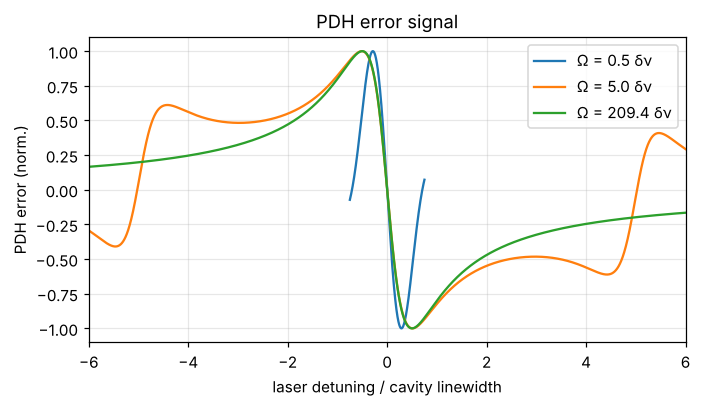

In [3]:
def pdh(L_mm=77.5, F=15000, lam_nm=685.0, Omega_MHz=27, target_Hz=1000, cte=5e-9):
    L = L_mm * 1e-3; fsr = c / (2 * L); dnu = fsr / F; nu0 = c / (lam_nm * 1e-9)
    frac = target_Hz / nu0
    return dict(FSR_GHz=fsr / 1e9, linewidth_kHz=dnu / 1e3, Omega_over_linewidth=Omega_MHz * 1e6 / dnu,
                dL_over_L=frac, dL_pm=frac * L * 1e12, dT_mK=target_Hz / (nu0 * cte) * 1e3), fsr, dnu

r_pdh, fsr, dnu = pdh()
print({k: f"{v:.4g}" for k, v in r_pdh.items()})

F_ = 15000; r_ = np.sqrt(1 - np.pi / F_)               # high-finesse estimate of the mirror amplitude reflectivity
def Fref(f): ph = np.exp(2j * np.pi * f / fsr); return r_ * (ph - 1) / (1 - r_**2 * ph)
for Om in (0.5 * dnu, 5 * dnu, 27e6):
    f = np.linspace(-1.5 * Om if Om < 5 * dnu else -6 * dnu, 1.5 * Om if Om < 5 * dnu else 6 * dnu, 4001)
    err = np.imag(Fref(f) * np.conj(Fref(f + Om)) - np.conj(Fref(f)) * Fref(f - Om))
    plt.plot(f / dnu, err / np.abs(err).max(), label=f"Ω = {Om/dnu:.1f} δν")
plt.xlim(-6, 6); plt.xlabel("laser detuning / cavity linewidth"); plt.ylabel("PDH error (norm.)"); plt.legend(); plt.title("PDH error signal")

## 4. Check against the page

In [4]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = dict(doppler=r_sas["doppler_MHz"], lamb=r_sas["lamb_dip_MHz"], contrast=r_sas["contrast"], pump_uW=r_sas["pump_uW"],
            nu1=r_beat["nu1_THz"], nu2=r_beat["nu2_THz"], lam2=r_beat["lam2_nm"], rf=r_beat["rf_dBm"], snr=r_beat["snr_dB"],
            fsr=r_pdh["FSR_GHz"], lw=r_pdh["linewidth_kHz"], ratio=r_pdh["Omega_over_linewidth"], dLL=r_pdh["dL_over_L"], dL=r_pdh["dL_pm"], dT=r_pdh["dT_mK"])
DECIMALS = dict(doppler=0, lamb=3, contrast=0, pump_uW=1, nu1=6, nu2=6, lam2=4, rf=1, snr=1, fsr=3, lw=3, ratio=1, dL=2, dT=2)
page = dict(doppler=378, lamb=7.402, contrast=72, pump_uW=4.3, nu1=446.799902, nu2=446.800130, lam2=670.9767, rf=-22.0, snr=88.9,
            fsr=1.934, lw=128.943, ratio=209.4, dLL=2.28e-12, dL=0.18, dT=0.46)
check(ours, page)

     doppler: notebook 378.3        page 378        OK
        lamb: notebook 7.402        page 7.402      OK
    contrast: notebook 72.29        page 72         OK
     pump_uW: notebook 4.32         page 4.3        OK
         nu1: notebook 446.8        page 446.8      OK
         nu2: notebook 446.8        page 446.8      OK
        lam2: notebook 671          page 670.977    OK
          rf: notebook -22.04       page -22        OK
         snr: notebook 88.92        page 88.9       OK
         fsr: notebook 1.934        page 1.934      OK
          lw: notebook 128.9        page 128.943    OK
       ratio: notebook 209.4        page 209.4      OK
         dLL: notebook 2.285e-12    page 2.28e-12   OK
          dL: notebook 0.1771       page 0.18       OK
          dT: notebook 0.457        page 0.46       OK
All values match the page.